# ABS Challenge System: Data Collection & Cleaning

**Project:** How Effective Is the MLB ABS (Automated Ball-Strike) System?
**Scope:** Triple-A, 2025 regular season, the season MLB.com's own analysis uses, so results can be checked against published numbers.

## Step 1: Collect

Each row is one batter on one team. The file holds two views of every batter: challenges the **batter** made (`n_challenges`, `n_overturns`) and challenges the **fielding team** made while that batter was at the plate (the `_against` columns). That second view is how the fielding side (catchers and pitchers combined) is measured from this single file.

Data source: MLB / Baseball Savant. <https://baseballsavant.mlb.com/leaderboard/abs-challenges>

In [2]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW, CLEAN, IMG = Path("data/raw"), Path("data/clean"), Path("images")
for p in (RAW, CLEAN, IMG):
    p.mkdir(parents=True, exist_ok=True)
FILE, LEVEL, YEAR = "abs-challenges-2025-batter.csv", "AAA", 2025

try:  # Google Colab: upload the CSV
    from google.colab import files
    for name in files.upload():
        Path(name).replace(RAW / name)
except ImportError:
    pass  # local run: put the CSV in data/raw/ yourself

Saving abs-challenges-2025-batter.csv to abs-challenges-2025-batter.csv


## Step 2: Load and inspect

In [3]:
raw = pd.read_csv(RAW / FILE, encoding="utf-8-sig")  # utf-8-sig strips the file's hidden BOM character
print(raw.shape)
print(raw[["level", "year"]].drop_duplicates())
raw[["entity_name", "team_abbr", "n_challenges", "n_overturns", "n_challenges_against", "n_overturns_against"]].head()

(667, 55)
  level  year
0   AAA  2025


,entity_name,team_abbr,n_challenges,n_overturns,n_challenges_against,n_overturns_against
0,CJ Alexander,SWB,17,11,11,4
1,Hayden Cantrelle,IOW,6,5,17,9
2,Davis Schneider,BUF,12,10,12,6
3,Jamie Westbrook,DUR,16,11,15,3
4,Rafael Lantigua,LHV,29,18,15,7


## Step 3: Clean

- confirm the expected columns exist and the file is Triple-A 2025
- drop empty rows and exact duplicates
- check that `overturns + confirms = challenges` and that Savant's rate matches the counts
- reshape from one wide row per batter into a tidy table with one row per batter and **role** (`batter` or `fielder`)
- drop rows with zero challenges (a batter whom the fielding team never challenged has no fielder-side rate)

`Max Muncy` appears twice because he played for two Triple-A teams, so a batter's identity is **name + team**, not name alone.

In [4]:
NEEDED = ["entity_name", "team_abbr", "parent_org", "level", "year",
          "n_challenges", "n_overturns", "n_confirms", "rate_overturns",
          "n_challenges_against", "n_overturns_against", "n_confirms_against", "rate_overturns_against"]
missing = [c for c in NEEDED if c not in raw.columns]
assert not missing, f"Savant changed its columns; missing {missing}. Columns are {list(raw.columns)}"
assert set(raw["level"]) == {LEVEL} and set(raw["year"]) == {YEAR}, "Wrong level or year in the file"

df = raw[NEEDED].dropna(how="all").drop_duplicates().reset_index(drop=True)
print(f"rows: {len(raw)} raw -> {len(df)} after dropping empty/duplicate rows")

for side, suffix in [("batter", ""), ("fielder", "_against")]:
    ch, ov, cf, rt = (df[f"{c}{suffix}"] for c in ("n_challenges", "n_overturns", "n_confirms", "rate_overturns"))
    ok_sum = ((ov + cf) == ch).all()
    n_bad_rate = int(((ov / ch.where(ch > 0) - rt).abs() > 0.001).sum())
    print(f"{side}: overturns+confirms==challenges: {ok_sum}; rows where Savant's rate disagrees with counts: {n_bad_rate}")

frames = []
for role, suffix in [("batter", ""), ("fielder", "_against")]:
    t = df[["entity_name", "team_abbr", "parent_org"]].copy()
    t["challenges"] = df[f"n_challenges{suffix}"]
    t["overturned"] = df[f"n_overturns{suffix}"]
    t["confirmed"] = df[f"n_confirms{suffix}"]
    t["role"] = role
    frames.append(t)
tidy = pd.concat(frames, ignore_index=True).rename(columns={"entity_name": "batter_name", "team_abbr": "batter_team"})
n0 = len(tidy)
tidy = tidy[tidy["challenges"] > 0].copy()
tidy["overturn_rate"] = tidy["overturned"] / tidy["challenges"]
print(f"tidy table: {n0} rows -> {len(tidy)} after dropping zero-challenge rows")

tidy.to_csv(CLEAN / "abs_challenges_aaa_2025_clean.csv", index=False)
tidy.head()

rows: 667 raw -> 667 after dropping empty/duplicate rows
batter: overturns+confirms==challenges: True; rows where Savant's rate disagrees with counts: 0
fielder: overturns+confirms==challenges: True; rows where Savant's rate disagrees with counts: 0
tidy table: 1334 rows -> 1278 after dropping zero-challenge rows


,batter_name,batter_team,parent_org,challenges,overturned,confirmed,role,overturn_rate
0,CJ Alexander,SWB,NYY,17,11,6,batter,0.647059
1,Hayden Cantrelle,IOW,CHC,6,5,1,batter,0.833333
2,Davis Schneider,BUF,TOR,12,10,2,batter,0.833333
3,Jamie Westbrook,DUR,TB,16,11,5,batter,0.687500
4,Rafael Lantigua,LHV,PHI,29,18,11,batter,0.620690


## Step 4: Query with SQL
Rates are computed as **total overturns / total challenges**, not as an average of per-batter rates, which would overweight batters with only a few challenges.

Note on `fielder`: those rows are challenges made *against* each batter, so `batter_team` is the batter's team, not the fielding team. That is why the team-level query below uses batters only.

In [5]:
con = sqlite3.connect(":memory:")
tidy.to_sql("challenges", con, index=False)
q = lambda sql: pd.read_sql_query(sql, con)

by_role = q('''
    SELECT role,
           SUM(challenges) AS challenges,
           SUM(overturned) AS overturned,
           ROUND(100.0 * SUM(overturned) / SUM(challenges), 1) AS overturn_pct
    FROM challenges
    GROUP BY role
''')
overall = q('''
    SELECT SUM(challenges) AS challenges, SUM(overturned) AS overturned,
           ROUND(100.0 * SUM(overturned) / SUM(challenges), 1) AS overturn_pct
    FROM challenges
''')
display(by_role); display(overall)

,role,challenges,overturned,overturn_pct
0,batter,4487,2022,45.1
1,fielder,4559,2449,53.7


,challenges,overturned,overturn_pct
0,9046,4471,49.4


In [6]:
team_batting = q('''
    SELECT batter_team, SUM(challenges) AS challenges, SUM(overturned) AS overturned,
           ROUND(100.0 * SUM(overturned) / SUM(challenges), 1) AS overturn_pct
    FROM challenges
    WHERE role = 'batter'
    GROUP BY batter_team
    ORDER BY overturn_pct DESC
''')
display(team_batting.head(3)); display(team_batting.tail(3))

,batter_team,challenges,overturned,overturn_pct
0,OKC,111,61,55.0
1,IOW,110,59,53.6
2,IND,92,48,52.2


,batter_team,challenges,overturned,overturn_pct
27,SYR,126,48,38.1
28,GWN,120,44,36.7
29,LOU,123,45,36.6


In [7]:
# Small samples produce extreme rates, so rank only batters with enough challenges.
MIN_CHAL = 10
leaders = q(f'''
    SELECT batter_name, batter_team, challenges, overturned,
           ROUND(100.0 * overturn_rate, 1) AS overturn_pct
    FROM challenges
    WHERE role = 'batter' AND challenges >= {MIN_CHAL}
    ORDER BY overturn_pct DESC
''')
by_sample = q('''
    SELECT CASE WHEN challenges < 10 THEN '1-9'
                WHEN challenges < 20 THEN '10-19'
                ELSE '20+' END AS challenge_count,
           COUNT(*) AS batters,
           ROUND(100.0 * MIN(overturn_rate), 0) AS min_pct,
           ROUND(100.0 * MAX(overturn_rate), 0) AS max_pct
    FROM challenges
    WHERE role = 'batter'
    GROUP BY challenge_count
''')
display(leaders.head(5)); display(leaders.tail(5)); display(by_sample)

,batter_name,batter_team,challenges,overturned,overturn_pct
0,Davis Schneider,BUF,12,10,83.3
1,Jose F Miranda,STP,12,9,75.0
2,Kellen Strahm,RR,11,8,72.7
3,Freddy Zamora,NAS,14,10,71.4
4,Luca Tresh,OMA,14,10,71.4


,batter_name,batter_team,challenges,overturned,overturn_pct
162,Blake Dunn,LOU,11,2,18.2
163,Kristian Campbell,WOR,11,2,18.2
164,Johnathan Rodríguez,COL,17,3,17.6
165,Zac Veen,ABQ,24,3,12.5
166,Daz Cameron,NOR,12,1,8.3


,challenge_count,batters,min_pct,max_pct
0,1-9,500,0.0,100.0
1,10-19,133,8.0,83.0
2,20+,34,13.0,67.0


## Step 5: Sanity-check against MLB's published numbers
MLB.com's Triple-A 2025 analysis reports about 50% overall, about 45% for batters and nearly 55% for fielders: <https://www.mlb.com/news/abs-challenge-system-statistical-breakdown-2025>.

In [8]:
PUBLISHED = {"batter": 45, "fielder": 55}
for _, r in by_role.iterrows():
    gap = r.overturn_pct - PUBLISHED[r.role]
    print(f"{r.role:8s} yours {r.overturn_pct:5.1f}%  MLB.com ~{PUBLISHED[r.role]}%  gap {gap:+.1f}  {'OK' if abs(gap) <= 5 else 'CHECK'}")
print(f"overall  yours {overall.overturn_pct[0]:5.1f}%  MLB.com ~50%")
print(f"total challenges in file: {overall.challenges[0]:,} (MLB.com reports 9,432)")

batter   yours  45.1%  MLB.com ~45%  gap +0.1  OK
fielder  yours  53.7%  MLB.com ~55%  gap -1.3  OK
overall  yours  49.4%  MLB.com ~50%
total challenges in file: 9,046 (MLB.com reports 9,432)


## Step 6: Chart for the site

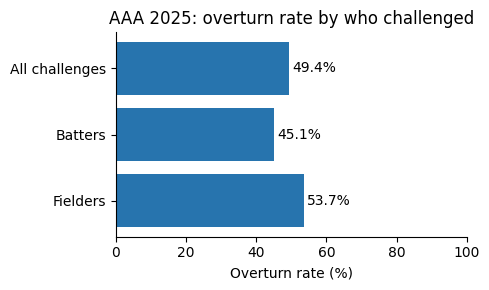

In [9]:
rows = [("All challenges", overall.overturn_pct[0])] + [(r.role.title() + "s", r.overturn_pct) for r in by_role.itertuples()]
fig, ax = plt.subplots(figsize=(5, 3))
ax.barh([r[0] for r in rows][::-1], [r[1] for r in rows][::-1], color="#2774AE")
for i, v in enumerate([r[1] for r in rows][::-1]):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 100); ax.set_xlabel("Overturn rate (%)")
ax.set_title(f"{LEVEL} {YEAR}: overturn rate by who challenged")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(IMG / "overturn_by_role.png", dpi=200)